## Knowledge Discovery and Interpretable Inference in Digital Twins via Rule Learning

This tutorial introduces neurosymbolic rule learning in digital twins for knowledge discovery and interpretable inference. 

Rule learning is the task of discovering patterns from data in the form of IF-THEN statements. In this tutorial, we will look into co-occurrence patterns.
For example, from the sensors of a water network we will learn rules such as:

&nbsp;&nbsp;&nbsp;&nbsp;**IF** `pipe_29_flow = high` **THEN** `leakage = yes` &nbsp;(true 100% of the time)

We propose a novel reframing of rule learning as a neurosymbolic problem, and this tutorial demonstrates it in a real-world use case of water distribution networks.

<div style="width:220px;height:220px;border:3px dashed #5E5A57;border-radius:12px;display:flex;align-items:center;justify-content:center;color:#5E5A57;font-size:20px;margin:16px 0">QR code</div>

**Or:** **ToDo: add a short form link to the project.**

### Table of Contents

1. Data and task: water distribution networks and leak detection. 
2. Rule learning: descriptive and interpretable predictive modelling.  
3. Neurosymbolic rule learning.
4. Rule Generalization
5. Can I use my own model instead?
6. What else can rules do?

## Before we start
Run the two cells below once (about 1 minute).

In [1]:
%pip install -q pyaerial xgboost pandas matplotlib scikit-learn


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [26]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/tutorial"):
        !git clone -q <REPO_URL> /content/tutorial
    %cd /content/tutorial
if not os.path.exists("tabprobe"):
    !git clone -q https://github.com/DiTEC-project/tabprobe.git
sys.path += ["src", "tabprobe"]

import logging, random, warnings
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import preprocess, tutorial_utils as tu

warnings.filterwarnings("ignore")
logging.disable(logging.INFO)
tu.set_style()

def seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

## Part 1 · What data do we have?
One year of sensor readings from a water network with two leaks.

**Where are the sensors and the leaks?**
LeakDB [1] simulates leaks in the Hanoi water network. We use the 18 sensors that are at most 2 pipes away from a leak.

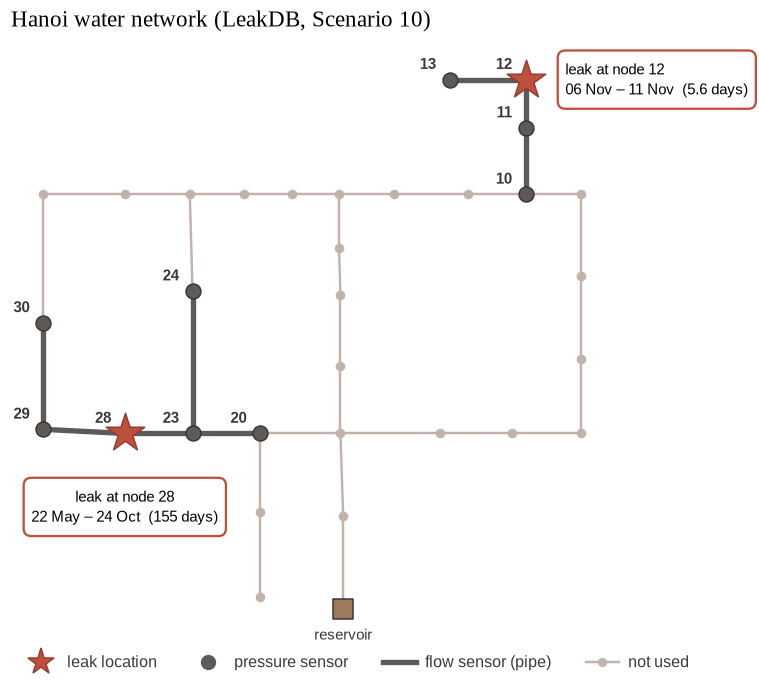

In [3]:
scenario = preprocess.download("Scenario-10")
table = preprocess.build_table(scenario, window="6h", hops=2)
sensors = [c for c in table.columns if c not in ("timestamp", "leakage")]

tu.draw_network(scenario, sensors)

**What is one row of our table?**
The average of every sensor over 6 hours, plus whether a leak was active.
Below: the pressure at leak node 28 and the flow in pipe 29, which feeds that node.

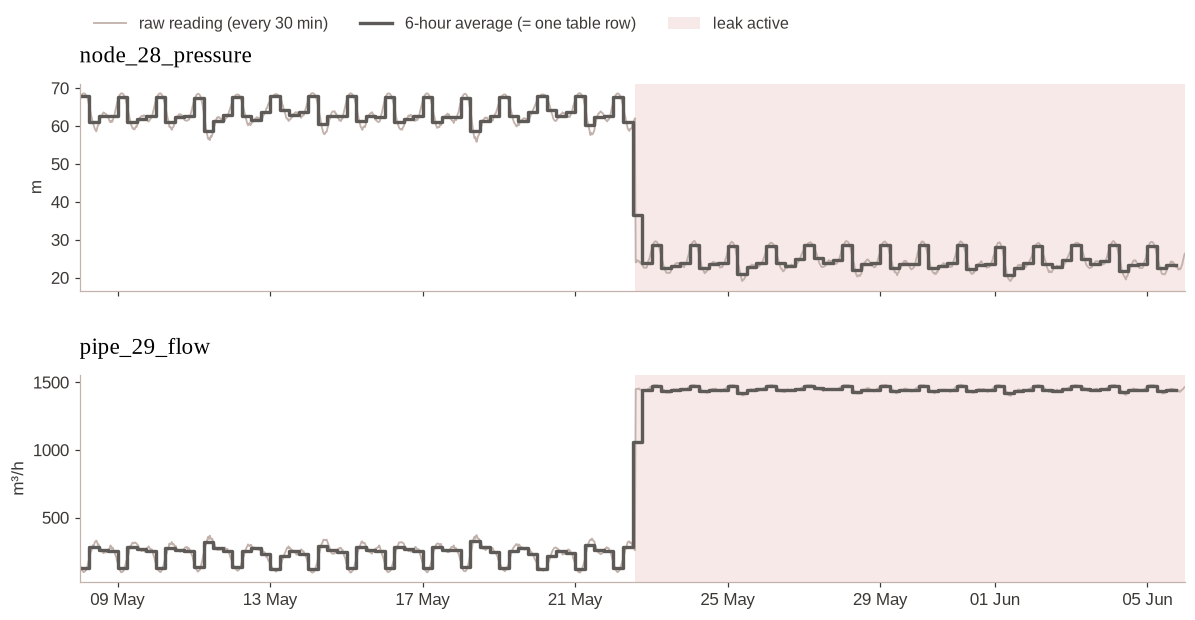

In [4]:
raw = preprocess.read_sensors(scenario)
tu.plot_aggregation(raw, table, ["node_28_pressure", "pipe_29_flow"], scenario)

In [5]:
cols = ["timestamp", "node_28_pressure", "pipe_29_flow", "node_12_pressure", "leakage"]
tu.show(table.loc[562:567, cols].round(1))   # 4 of the 18 sensors, as the leak at node 28 starts

timestamp,node_28_pressure,pipe_29_flow,node_12_pressure,leakage
21 May 12:00,62.5,258.0,63.5,0
21 May 18:00,62.7,253.2,63.7,0
22 May 00:00,67.8,129.0,68.0,0
22 May 06:00,61.0,283.8,62.3,0
22 May 12:00,36.5,1059.6,62.2,1
22 May 18:00,23.8,1446.9,61.5,1


**Why low / mid / high?**
Rules speak in categories, not numbers, so each reading becomes low, mid or high.

In [6]:
data = tu.discretize(table)
tu.show(data.loc[562:567, cols[1:]])

node_28_pressure,pipe_29_flow,node_12_pressure,leakage
high,low,high,no
high,low,high,no
high,low,high,no
high,low,high,no
mid,high,high,yes
low,high,high,yes


## Part 2 · Why not simply list all the rules?
Because there are far too many, and most of them tell us nothing new.

**What is a rule?**

&nbsp;&nbsp;&nbsp;&nbsp;**IF** `pipe_29_flow = high` **THEN** `leakage = yes`

- **support**: how often IF and THEN are true *together*
- **confidence**: how often THEN is true, *when IF is true*

**How many rules could there be?** Even for our small table:

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.


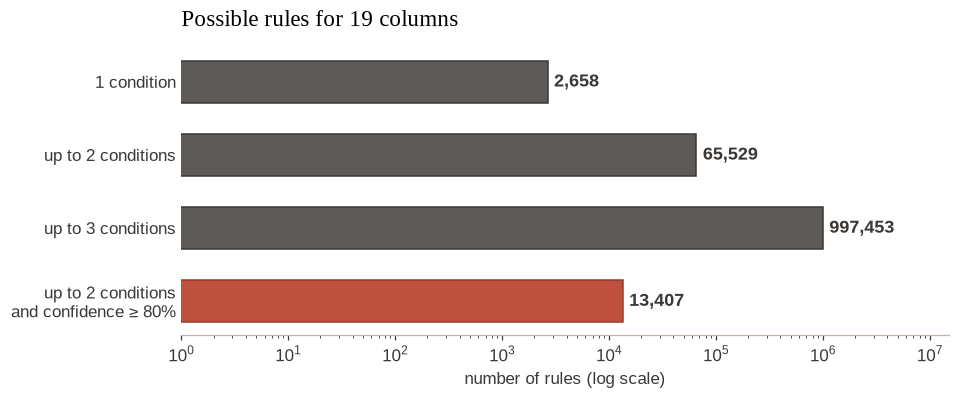

In [7]:
possible = tu.count_possible_rules(data, max_len=3)
all_rules = tu.mine_all_rules(data, max_len=2)          # classical exhaustive search
strong = all_rules[all_rules.confidence >= 0.8]

tu.plot_rule_explosion(possible, len(strong))

**Is a rule with high confidence always useful?**
No. We also have to compare it with the **base rate**: how often THEN is true *anyway*.

In [8]:
tu.explain_examples(data, [
    ({"pipe_11_flow": "low"},        ("node_12_pressure", "high"), "mostly high anyway"),
    ({"node_12_pressure": "high"},   ("pipe_10_flow", "low"),      "almost always low anyway"),
    ({"pipe_29_flow": "high"},       ("leakage", "yes"),           "far above base rate"),
    ({"pipe_10_flow": "low", "pipe_29_flow": "high"}, ("leakage", "yes"), "repeats the rule above"),
])

Rule,Support,Confidence,Base rate,Why
pipe_11_flow = low → node_12_pressure = high,86%,88%,86%,mostly high anyway
node_12_pressure = high → pipe_10_flow = low,86%,100%,98%,almost always low anyway
pipe_29_flow = high → leakage = yes,42%,100%,44%,far above base rate
pipe_10_flow = low AND pipe_29_flow = high → leakage = yes,42%,100%,44%,repeats the rule above


So we want **a few rules that tell us something new**, without listing millions of them.

## Part 3 · How does Aerial+ find the useful rules?
A neural network learns the patterns in the table, then we probe it with queries [2, 3].

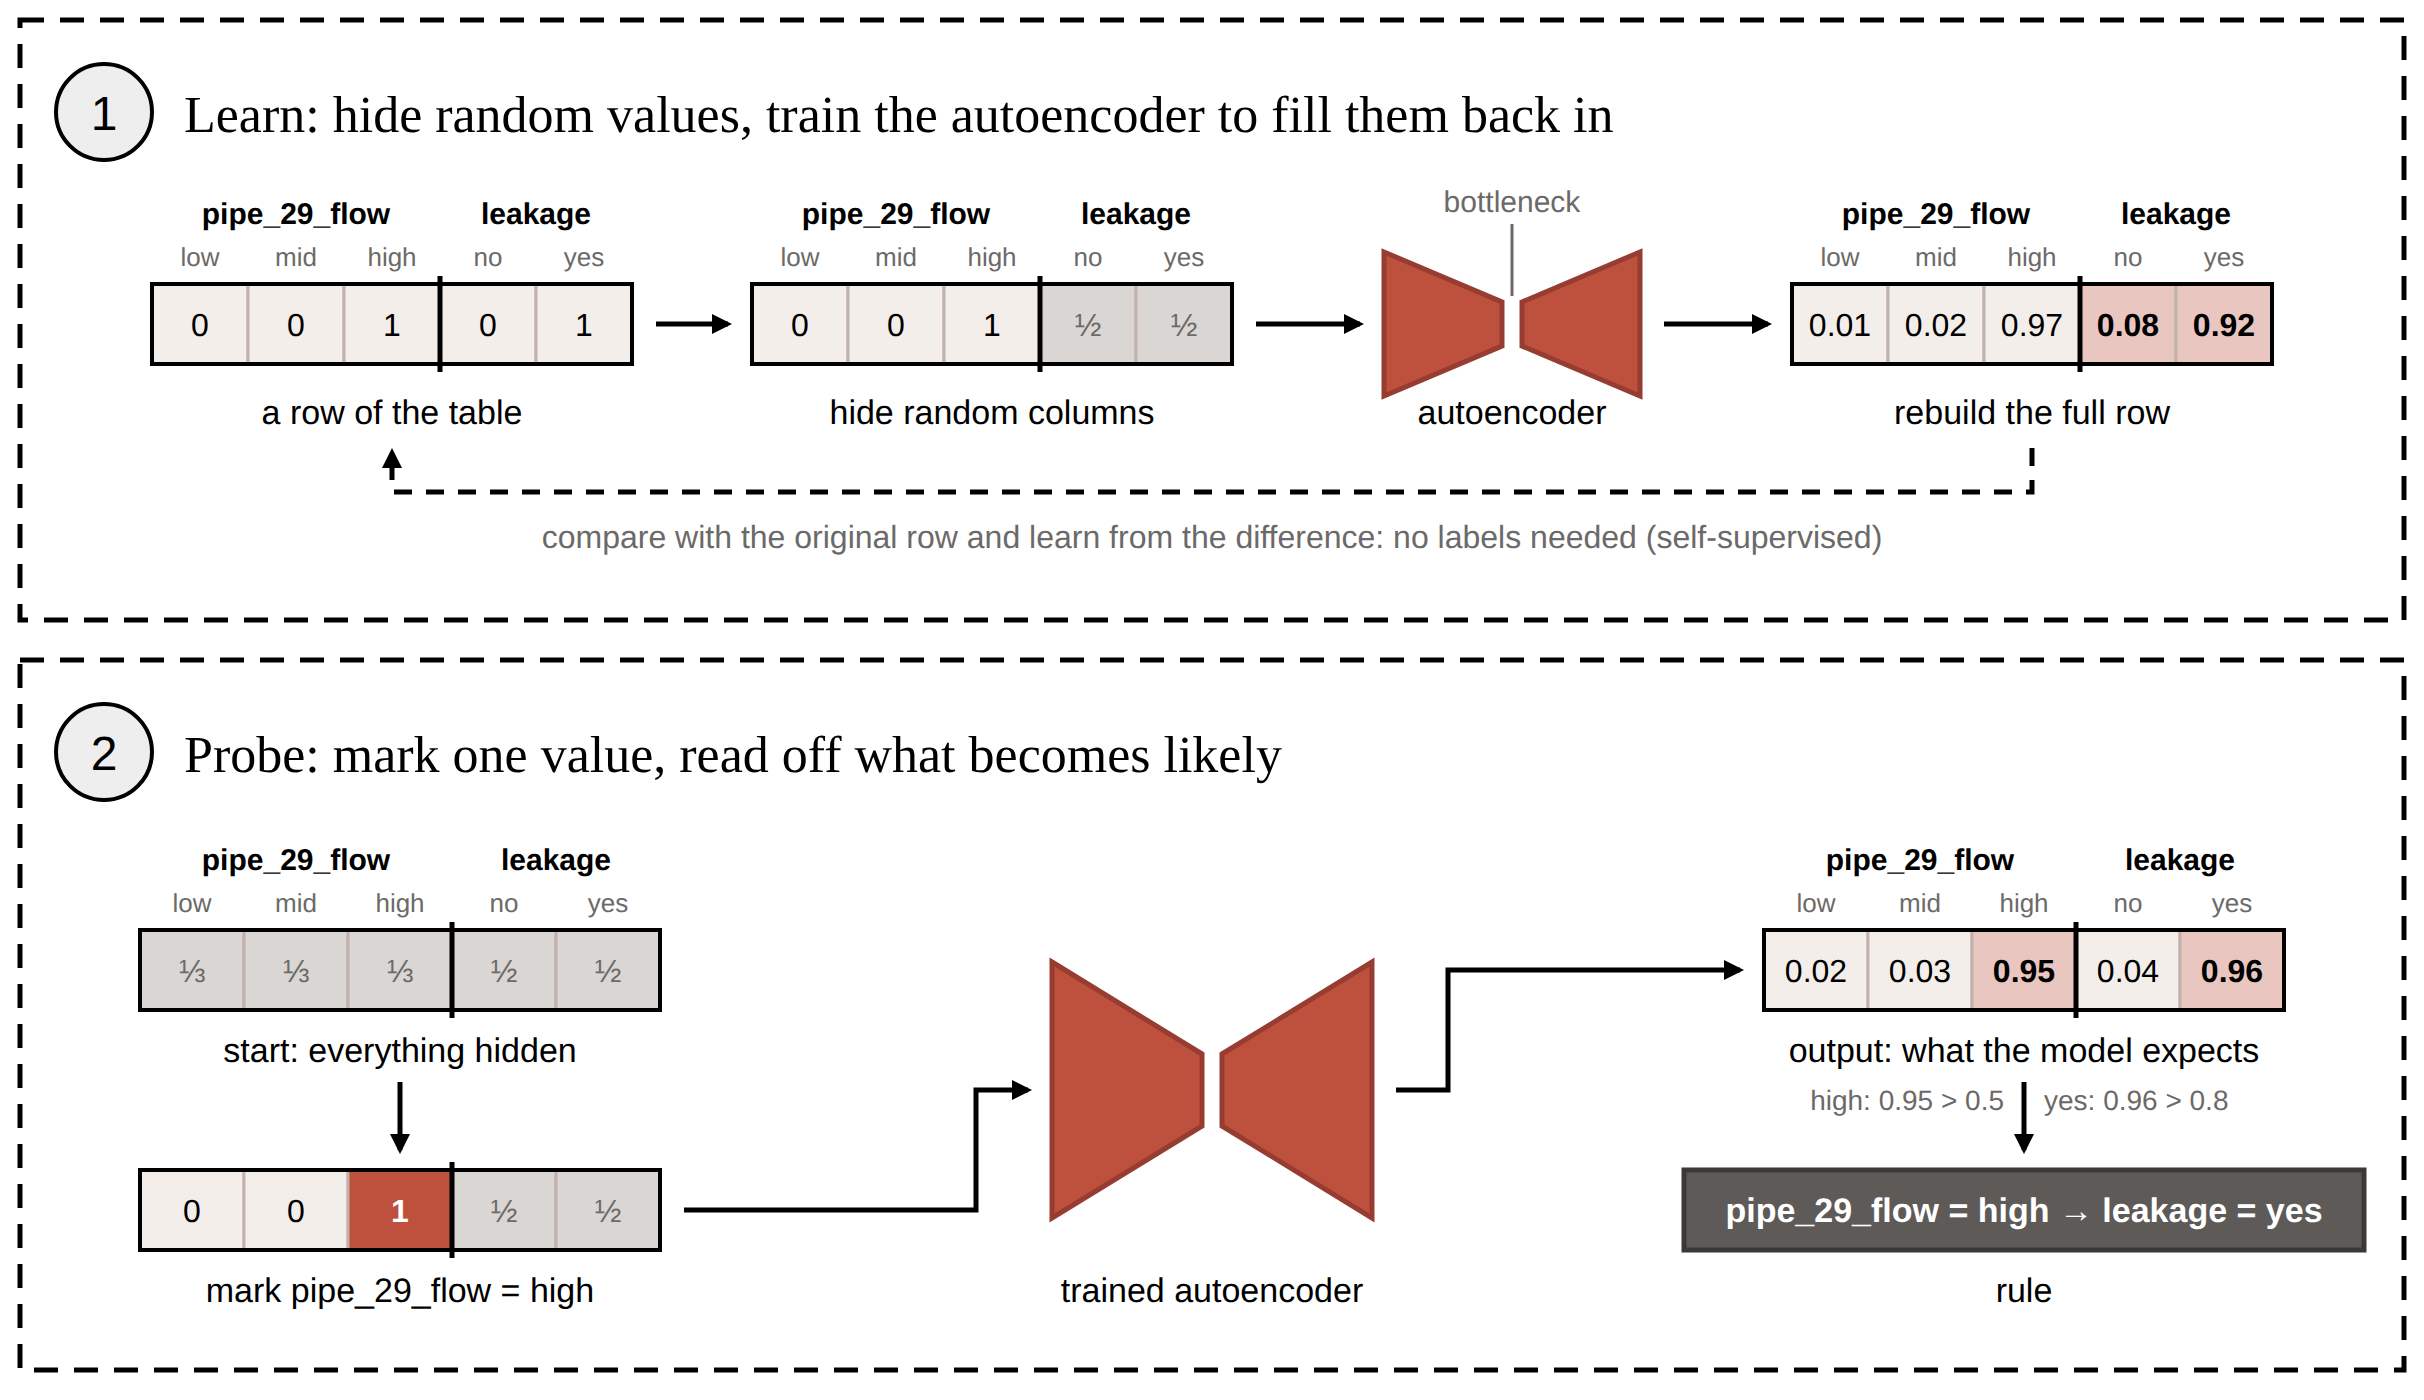

**Let's try it:** learn rules that say something about `leakage`.

In [13]:
from aerial import model, rule_extraction

seed(0)
autoencoder = model.train(data, layer_dims=[16], epochs=2, show_progress=False)
rules = rule_extraction.generate_rules(autoencoder, target_classes=["leakage"])["rules"]

print(len(rules), "rules")
tu.rules_table(rules, n=20)

88 rules


IF,THEN,support,confidence
pipe_23_flow = low,leakage = no,46%,97%
pipe_29_flow = high,leakage = yes,42%,100%
node_28_pressure = low,leakage = yes,42%,100%
node_29_pressure = low,leakage = yes,42%,100%
pipe_30_flow = low,leakage = yes,42%,100%
pipe_31_flow = low,leakage = yes,42%,100%
pipe_23_flow = high,leakage = yes,32%,100%
node_28_pressure = high AND pipe_31_flow = high,leakage = no,56%,97%
node_28_pressure = high AND pipe_30_flow = high,leakage = no,56%,97%
node_28_pressure = high AND node_29_pressure = high,leakage = no,56%,97%


**What do support and confidence look like?**
Each lane shows when that side of the rule is true. Try another rule by changing `i`.

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.


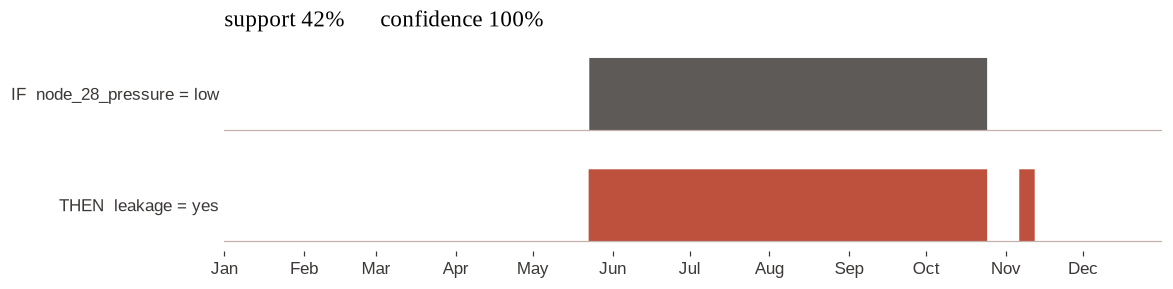

In [10]:
i = 0
tu.plot_rule_timeline(data, table.timestamp, rules[i])

**Which rules describe the leaks?**
We ask only for rules that end in `leakage = yes`.

In [11]:
leak_rules = rule_extraction.generate_rules(autoencoder, target_classes=[{"leakage": "yes"}])["rules"]

print(len(leak_rules), "leakage rules")
tu.rules_table(leak_rules, n=10)

30 leakage rules


IF,THEN,support,confidence
pipe_29_flow = high,leakage = yes,42%,100%
node_28_pressure = low,leakage = yes,42%,100%
node_29_pressure = low,leakage = yes,42%,100%
pipe_30_flow = low,leakage = yes,42%,100%
pipe_31_flow = low,leakage = yes,42%,100%
pipe_23_flow = high,leakage = yes,32%,100%
pipe_11_flow = low AND pipe_29_flow = high,leakage = yes,42%,100%
pipe_10_flow = low AND pipe_29_flow = high,leakage = yes,42%,100%
node_28_pressure = low AND pipe_11_flow = low,leakage = yes,42%,100%
pipe_11_flow = low AND pipe_31_flow = low,leakage = yes,42%,100%


**Do they make sense?**
They point to the sensors around the leaks, so we can check every rule on the map.

findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.


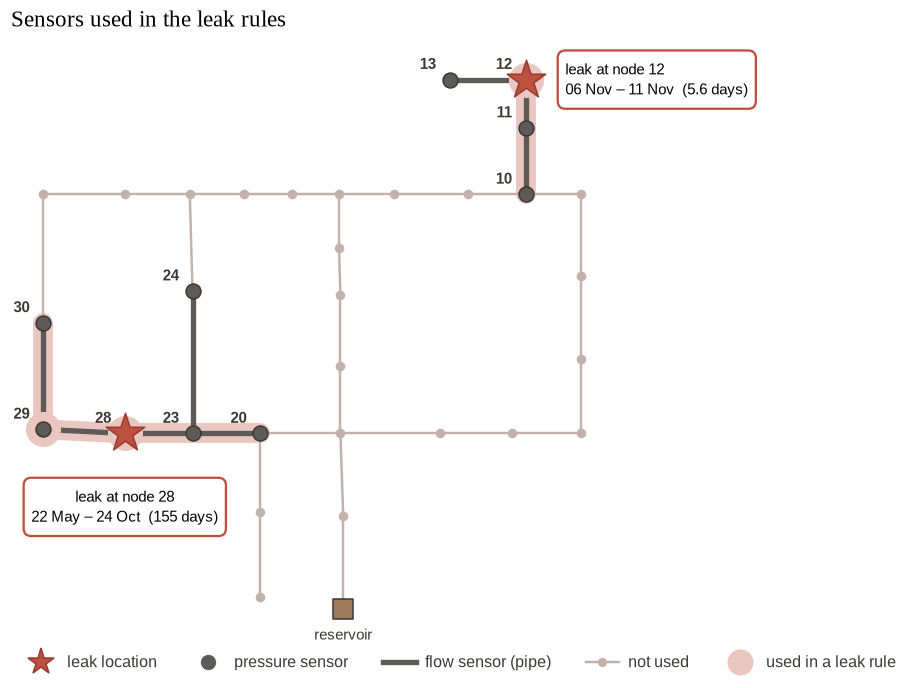

In [12]:
tu.draw_network(scenario, sensors, highlight=tu.rule_sensors(leak_rules), title_text="Sensors used in the leak rules")

**Can I control how many rules I get?**
Yes. The autoencoder squeezes each row through a **bottleneck**: the smaller it is, the fewer patterns survive.

Other settings: `min_rule_frequency` (≈ support), `min_rule_strength` (≈ confidence), `max_antecedents` (rule length).

In [ ]:
by_size = {}
for size in [4, 16, 32]:
    seed(0)
    ae = model.train(data, layer_dims=[size], epochs=2, show_progress=False)
    by_size[size] = rule_extraction.generate_rules(ae, target_classes=[{"leakage": "yes"}])["rules"]

tu.plot_bottleneck(by_size)

In [ ]:
tu.rules_table(by_size[4])

## Part 4 · Do the rules hold on new data?
We learn rules on part of the year and check them on weeks the model has never seen.

In [ ]:
week = table.timestamp.dt.isocalendar().week.values
test = week % 4 == 0
tu.plot_split(table.timestamp, test, table)

**Are the rules still confident on unseen weeks?**
Each dot is one rule learned on the training weeks.

In [ ]:
seed(0)
ae = model.train(data[~test], layer_dims=[16], epochs=2, show_progress=False)
train_rules = rule_extraction.generate_rules(ae, target_classes=[{"leakage": "yes"}])["rules"]

tu.plot_train_vs_test(train_rules, data[test])

**Can the rules detect leaks?**
Raise an alarm whenever a rule fires. Every alarm comes with its reason: the rule itself.

In [ ]:
alarm = np.any([tu.fires(r["antecedents"], data[test]) for r in train_rules], axis=0)
tu.plot_alarms(table.timestamp[test], data[test], alarm)

## Part 5 · Can I use my own model instead?
Yes. TabProbe turns any model that predicts a column from the other columns into a rule learner [6].

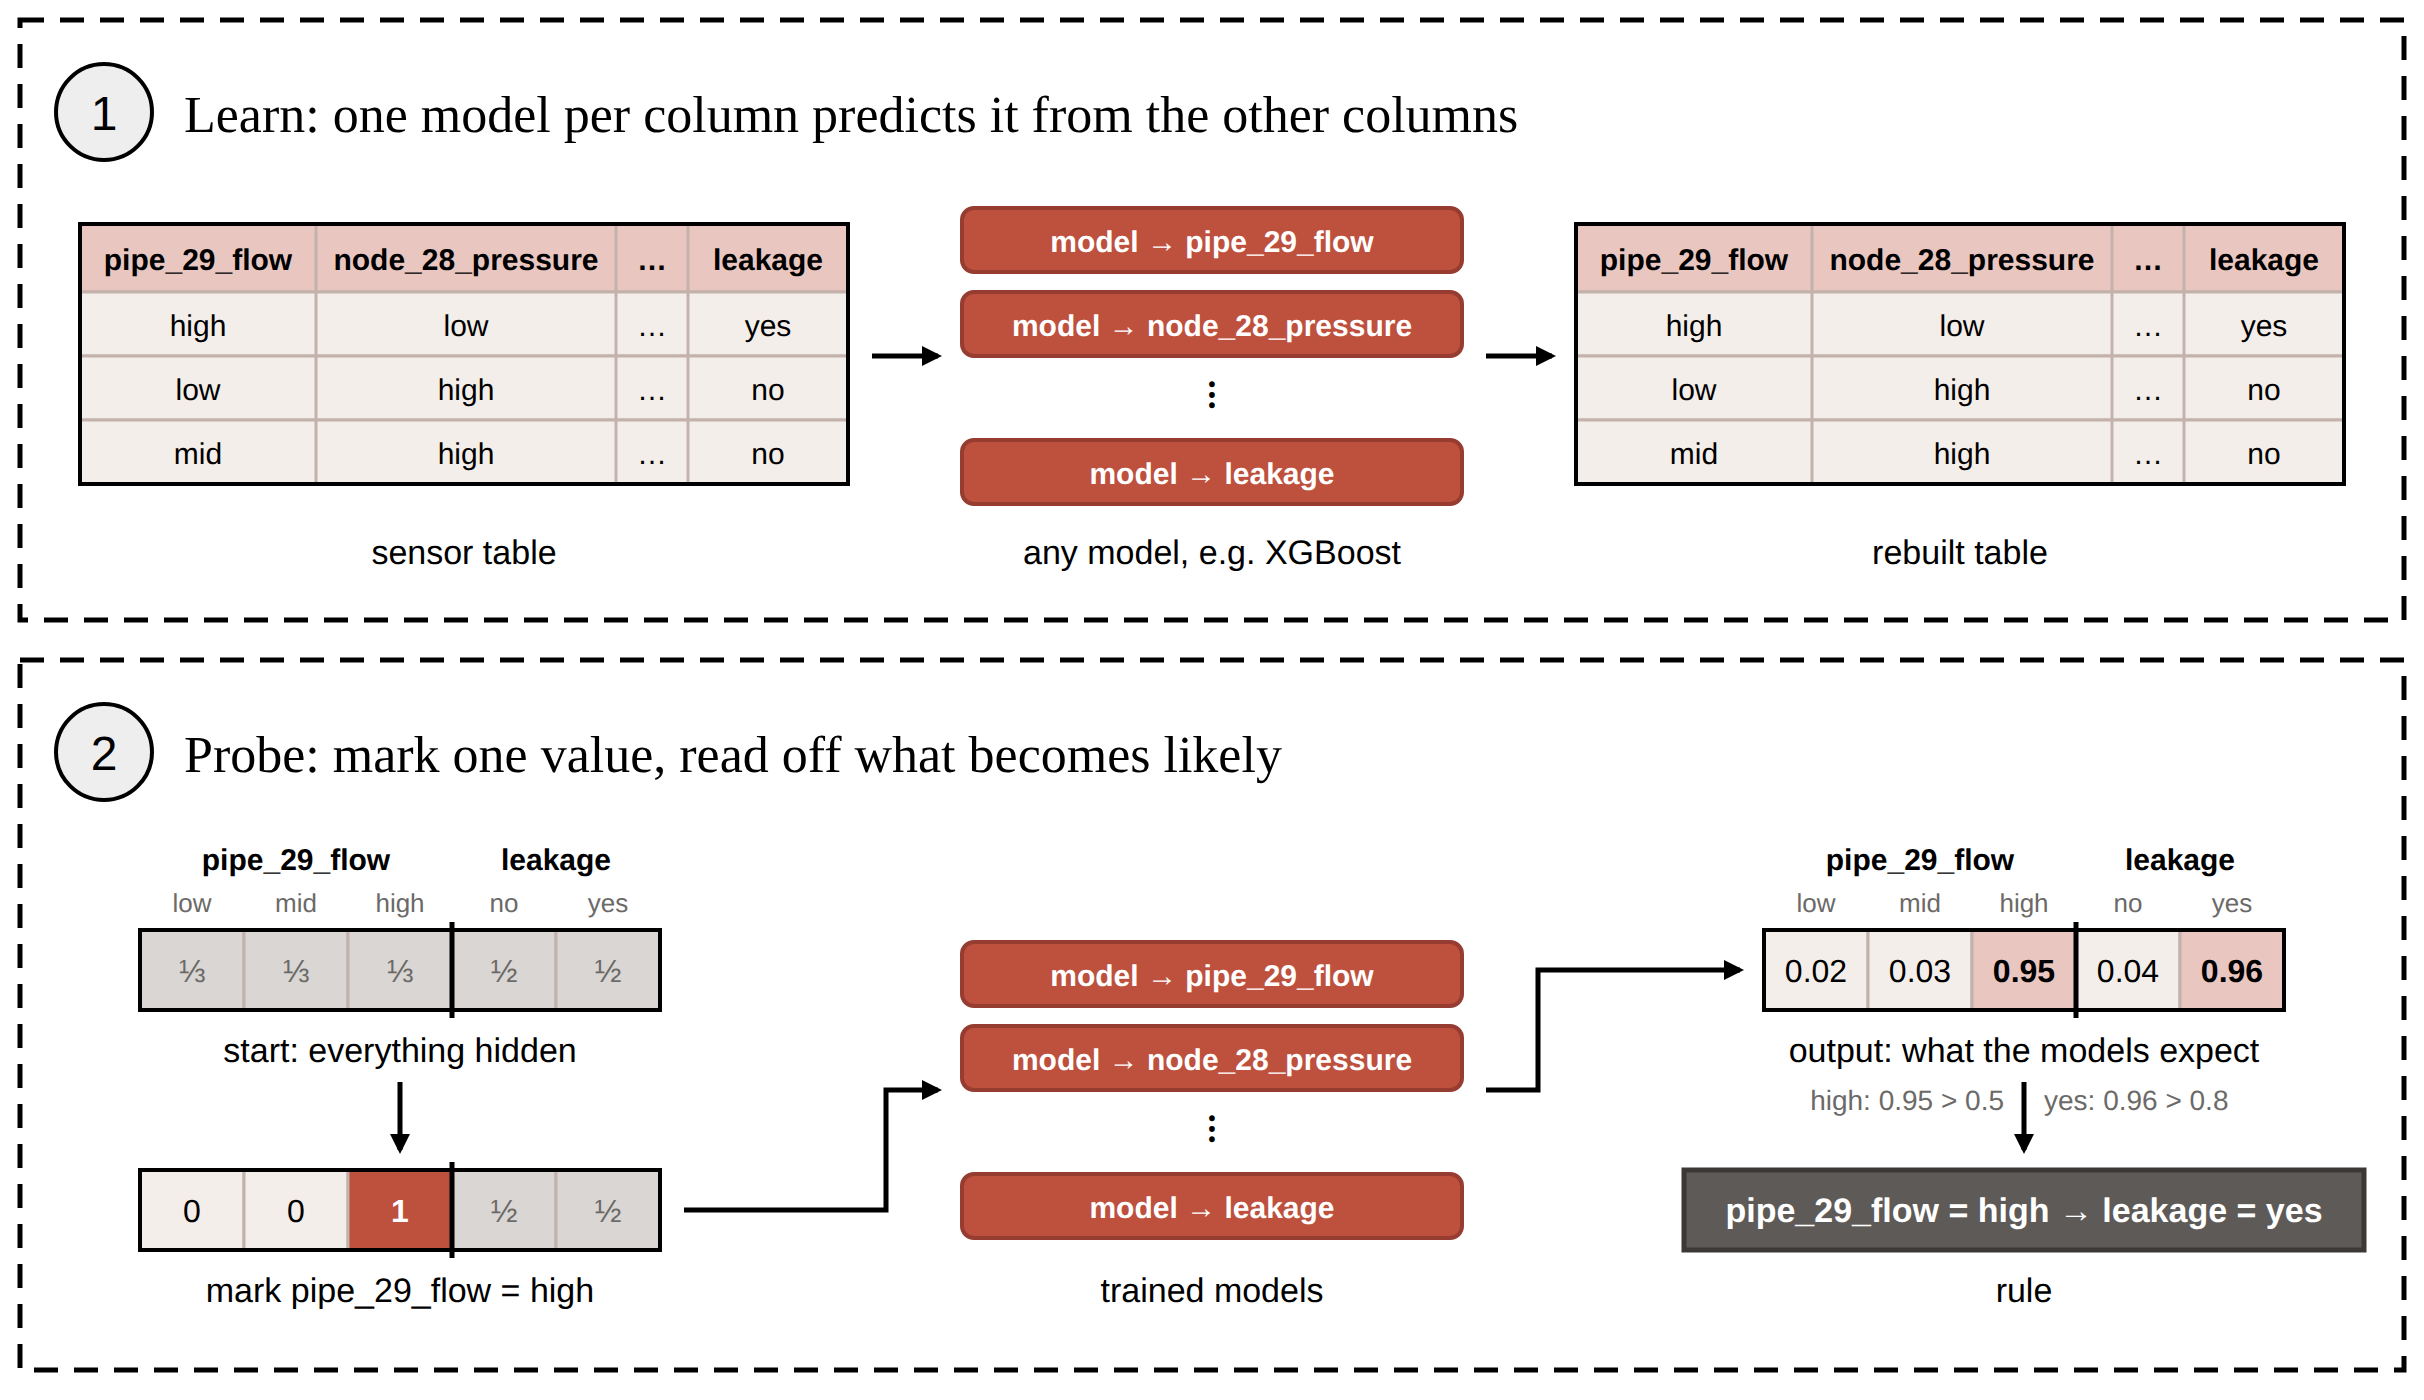

Same two steps as Aerial+, only the model changes: tabular foundation models (TabPFN, TabICL, TabDPT), XGBoost, random forests, …

**Let's try it with XGBoost:**

In [ ]:
from src.wrapper import TabProbe

miner = TabProbe(method="xgboost", max_antecedents=2, ant_similarity=0.5, cons_similarity=0.8)
xgb_rules = miner.mine_rules(data, metrics=["support", "confidence"])
xgb_leak_rules = [r for r in xgb_rules if r["consequent"] == {"feature": "leakage", "value": "yes"}]

print(len(xgb_rules), "rules,", len(xgb_leak_rules), "about leakage")

**Can we trust every rule?**
XGBoost is often over-confident, so we keep only the rules that also hold on the data.

In [ ]:
xgb_leak_rules = [r for r in xgb_leak_rules if r["confidence"] >= 0.8]
tu.rules_table(xgb_leak_rules, n=10)

**Do both methods find the same leaks?**

In [ ]:
tu.compare_networks(scenario, sensors, {"Aerial+": leak_rules, "TabProbe + XGBoost": xgb_leak_rules})

**Your turn:** change `method="xgboost"` to `"random_forest"`.
With a GPU runtime, try `"tabpfn"` or `"tabicl"` (`pip install tabpfn` / `tabicl`).

## Part 6 · What else can rules do?
Three more questions we answered in recent papers.

- **What if I don't want to choose low / mid / high myself?**
  DiffNARM learns the ranges together with the rules [7].
- **What if I have very few rows but thousands of columns**?
  Tabular foundation models help Aerial+ [5] and TabProbe [6] learn from small data.
- **Can rules know the network itself?**
  With a **knowledge graph** of the network, rules can say *"IF a flow sensor in a pipe longer than L reads V1, THEN the pressure sensor at the connected junction reads V2"* [4].

**Code:** [PyAerial](https://github.com/DiTEC-project/pyaerial) · [TabProbe](https://github.com/DiTEC-project/tabprobe) · [DiffNARM](https://github.com/DiTEC-project/diffnarm)

## References

1. Vrachimis, S. G., Kyriakou, M. S., Eliades, D. G., & Polycarpou, M. M. (2018). LeakDB: A benchmark dataset for leakage diagnosis in water distribution networks. *WDSA/CCWI Joint Conference*.
2. Karabulut, E., Groth, P., & Degeler, V. (2025). Neurosymbolic association rule mining from tabular data. *NeSy 2025*, PMLR 284, 565–588.
3. Karabulut, E., Groth, P., & Degeler, V. (2025). PyAerial: Scalable association rule mining from tabular data. *SoftwareX*, 31, 102341.
4. Karabulut, E., Groth, P., & Degeler, V. (2025). Learning semantic association rules from Internet of Things data. *Neurosymbolic Artificial Intelligence*, 1. doi:10.1177/29498732251377518
5. Karabulut, E., Daza, D., Groth, P., & Degeler, V. (2025). Discovering association rules in high-dimensional small tabular data. *ANSyA@ECAI 2025*. arXiv:2509.20113
6. Karabulut, E., Daza, D., Groth, P., Schut, M. C., & Degeler, V. (2026). Tabular foundation models can learn association rules. arXiv:2602.14622
7. Karabulut, E., et al. Differentiable numerical association rule learning. *(TODO: venue)*
8. Hollmann, N., Müller, S., Purucker, L., et al. (2025). Accurate predictions on small data with a tabular foundation model. *Nature*, 637, 319–326.
9. Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *KDD 2016*.
10. Agrawal, R., & Srikant, R. (1994). Fast algorithms for mining association rules. *VLDB 1994*.